In [13]:
import numpy as np
import os
import pandas as pd
import pickle
import joblib
import matplotlib.pyplot as plt
from skimage import exposure
from PIL import Image
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from skimage.feature import graycomatrix, graycoprops

#### Loading dataset

In [14]:
base_path = "C:\\Users\\Dell\\Desktop\\Nowy folder\\PJATK\\III SEMESTR\\ZUM\\breast-cancer-detection"
split = ["train", "test", "valid"]
classes = ["0", "1"]

def load_datasets(split):
    paths = []
    labels = []
    for label in classes:
        folder = os.path.join(base_path, split, label)
        for img in os.listdir(folder):
            paths.append(os.path.join(folder, img))
            labels.append(label)
    return pd.DataFrame({"path": paths, "label": labels})   

df_train = load_datasets("train")
df_test = load_datasets("test")
df_valid = load_datasets("valid")


In [15]:
img_size = 224

#### Preprocessing 

In [16]:
img_size = 224

def preprocess2(df):
    X_flat = []
    X_rad  = []
    y      = []

    for i in tqdm(range(len(df))):
        path  = df.iloc[i]["path"]
        label = int(df.iloc[i]["label"])

        img = Image.open(path).convert("L").resize((img_size, img_size))
        arr = np.array(img).astype(np.float32)

        arr = arr / 255.0

        if arr.mean() > 0.6:
            arr = 1.0 - arr

        arr = exposure.equalize_adapthist(arr, clip_limit=0.03)
        arr = np.clip(arr, 0, 1)

        X_flat.append(arr.flatten())

        arr_u8 = (arr * 255).astype(np.uint8)

        g = graycomatrix(
            arr_u8,
            distances=[1],
            angles=[0],
            levels=256,
            symmetric=True,
            normed=True
        )

        feats = [
            graycoprops(g, "contrast")[0,0],
            graycoprops(g, "dissimilarity")[0,0],
            graycoprops(g, "homogeneity")[0,0],
            graycoprops(g, "energy")[0,0],
            graycoprops(g, "correlation")[0,0],
            graycoprops(g, "ASM")[0,0],
            arr.mean(),
            arr.std(),
            arr.var(),
            -np.sum(np.histogram(arr_u8,256,(0,256),density=True)[0] *
                    np.log2(np.histogram(arr_u8,256,(0,256),density=True)[0] + 1e-8))
        ]

        X_rad.append(feats)
        y.append(label)

    return np.array(X_flat), np.array(X_rad), np.array(y)


In [17]:
X_train_flat, X_train_rad, y_train = preprocess2(df_train)
X_valid_flat, X_valid_rad, y_valid = preprocess2(df_valid)
X_test_flat,  X_test_rad,  y_test  = preprocess2(df_test)

100%|████████████████████████████████████████████████████████████████████████████████| 336/336 [00:08<00:00, 41.94it/s]


In [18]:
print(X_train_flat.shape, X_train_rad.shape, y_train.shape)

(2372, 50176) (2372, 10) (2372,)


In [19]:
print(X_train_flat.min(), X_train_flat.max(), X_train_flat.mean())

0.0 1.0 0.20293878


#### Save datasets with joblib

In [20]:
joblib.dump({
    "X_train_flat":X_train_flat,"X_train_rad":X_train_rad,"y_train":y_train,
    "X_valid_flat":X_valid_flat,"X_valid_rad":X_valid_rad,"y_valid":y_valid,
    "X_test_flat":X_test_flat, "X_test_rad":X_test_rad, "y_test":y_test
},"datasets2.pkl")

['datasets2.pkl']

#### Standarization

In [17]:
scaler = StandardScaler()
X_flat = scaler.fit_transform(X_train_flat)

In [19]:
X_flat

array([[ 0.50878934,  0.56647154,  0.64959171, ...,  2.10260006,
         2.01703879,  1.87185325],
       [ 2.02895455,  2.05015362,  2.05234451, ...,  2.10260006,
         2.01703879,  1.87185325],
       [-0.70734283, -0.699022  , -0.68791678, ..., -0.65311734,
        -0.71603937, -0.7683312 ],
       ...,
       [-0.70734283, -0.699022  , -0.68791678, ...,  1.24963991,
         1.5940624 ,  1.55754558],
       [ 0.66080586,  0.64283753,  0.50822902, ..., -0.65311734,
        -0.71603937, -0.7683312 ],
       [-0.70734283, -0.699022  , -0.68791678, ..., -0.65311734,
        -0.71603937, -0.7683312 ]], shape=(2372, 16384))

#### Preprocessing for PCA approach

In [18]:
var = np.var(abs(X_flat), axis=0)
print(np.mean(var))

0.3532361036404973


In [19]:
pca = PCA()
pca.fit(X_flat)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


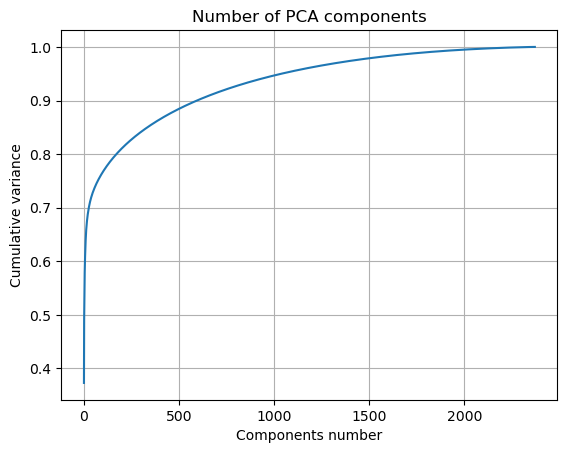

In [20]:
cum_var = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cum_var)
plt.xlabel("Components number")
plt.ylabel("Cumulative variance")
plt.title("Number of PCA components")
plt.grid(True)
plt.show()

In [21]:
n_comp = np.argmax(cum_var >= 0.90) + 1
n_comp

np.int64(1040)

In [34]:
for n in [20, 40, 60, 80, 100, 120, 135, 140]:
    pca = PCA(n_components=n)
    Xp = pca.fit_transform(X_train_flat)
    rf = RandomForestClassifier(class_weight='balanced', random_state=42)
    rf.fit(Xp, y_train)
    acc = rf.score(pca.transform(X_valid_flat), y_valid)
    print(n, acc)

20 0.6251851851851852
40 0.6014814814814815
60 0.6237037037037036
80 0.6192592592592593
100 0.6192592592592593
120 0.6385185185185185
135 0.6118518518518519
140 0.6325925925925926
